# Data Preprocessing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [2]:
DATA_DIR = Path('../data')

df = pd.read_csv(DATA_DIR / "twcs_filtered_labeled_1.csv")
df.head()

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,label
0,2,115712.0,True,Tue Oct 31 22:11:45 +0000 2017,@sprintcare and how do you propose we do that,NaN,1.0,General / Other
1,3,115712.0,True,Tue Oct 31 22:08:27 +0000 2017,@sprintcare I have sent several private messag...,1,4.0,General / Other
2,5,115712.0,True,Tue Oct 31 21:49:35 +0000 2017,@sprintcare I did.,4,6.0,General / Other
3,8,115712.0,True,Tue Oct 31 21:45:10 +0000 2017,@sprintcare is the worst customer service,"9,6,10",NaN,General / Other
4,12,115713.0,True,Tue Oct 31 22:04:47 +0000 2017,@sprintcare You gonna magically change your co...,"11,13,14",15.0,General / Other


In [3]:
# Drop examples with a null value in the text column
df = df.dropna(subset=['text'])
df['text'].isna().sum()

np.int64(0)

In [4]:
# Remove @mentions from the text feature
df["clean_text"] = df["text"].str.replace(
    r"@\w+",
    "",
    regex=True
)

# Verify removal
print("Rows with @mentions before:",
      df["text"].str.contains(r"@\w+", regex=True, na=False).sum())

print("Rows with @mentions after:",
      df["clean_text"].str.contains(r"@\w+", regex=True, na=False).sum())

Rows with @mentions before: 76396
Rows with @mentions after: 0


In [5]:
# Remove URLs from the text feature
print("Rows with URLs before:",
      df["clean_text"].str.contains(
          r"https?://\S+", regex=True, na=False
      ).sum())

df["clean_text"] = df["clean_text"].str.replace(
    r"https?://\S+",
    "",
    regex=True
)

# Verify removal
print("Rows with URLs after:",
      df["clean_text"].str.contains(
          r"https?://\S+", regex=True, na=False
      ).sum())

Rows with URLs before: 6272
Rows with URLs after: 0


In [6]:
# Decode HTML entities (e.g., &amp; to &, &lt; to <)
import html

html_pattern = r"&(?:[A-Za-z]+|#\d+|#x[0-9A-Fa-f]+);"

print("Rows with HTML entities before:",
      df["clean_text"].str.contains(
          html_pattern, regex=True, na=False
      ).sum())

df["clean_text"] = df["clean_text"].apply(
    lambda x: html.unescape(x) if isinstance(x, str) else x
)

# Verify decoding
print("Rows with HTML entities after:",
      df["clean_text"].str.contains(
          html_pattern, regex=True, na=False
      ).sum())

Rows with HTML entities before: 2439
Rows with HTML entities after: 0


In [7]:
# Display examples where preprocessing changed the original text
changed_rows = df["text"] != df["clean_text"]

df.loc[changed_rows, ["text", "clean_text"]].sample(80)

,text,clean_text
36071,@469701 @TMobileHelp @115913 Because it's not ...,Because it's not worth much anymore.
45357,@TMobileHelp @115913 Give me email id.. I will...,Give me email id.. I will send you all the d...
104,@VerizonSupport @115725 ... when your “gigabit...,... when your “gigabit” internet is so slow ...
3522,@TMobileHelp And I have responded.,And I have responded.
63589,"@VerizonSupport I did that like 2x this week, ...","I did that like 2x this week, it works for ab..."
...,...,...
29679,@VerizonSupport This is what I'm seeing. It ju...,This is what I'm seeing. It just shut off.......
58790,@VerizonSupport 🖕🏼🖕🏼,🖕🏼🖕🏼
67350,@sprintcare I sent you a DM an hour ago still ...,I sent you a DM an hour ago still waiting to ...
44796,@115911 @TMobileHelp y'all got any deals for s...,y'all got any deals for switching to you 👀👀


In [8]:
# Confirm the cleaned dataset has the original structure
print(df.shape)
print(df.columns.tolist())

print("Remaining @mentions:",
      df["text"].str.contains(r"@\w+", regex=True, na=False).sum())

print("Remaining URLs:",
      df["text"].str.contains(r"https?://\S+", regex=True, na=False).sum())

(76396, 9)
['tweet_id', 'author_id', 'inbound', 'created_at', 'text', 'response_tweet_id', 'in_response_to_tweet_id', 'label', 'clean_text']
Remaining @mentions: 76396
Remaining URLs: 6272


In [9]:
# Update the original text feature with the cleaned text and restore the original dataset structure
df["text"] = df["clean_text"]
df.drop(columns=["clean_text"], inplace=True)

print(df.shape)
print(df.columns.tolist())

(76396, 8)
['tweet_id', 'author_id', 'inbound', 'created_at', 'text', 'response_tweet_id', 'in_response_to_tweet_id', 'label']


In [10]:
# Dropping 'General / Other' label from data by setting examples with it to NaN and then dropping NaN values by the label column
df['label'] = np.where(df['label'] == "General / Other", np.nan, df['label'])
df = df.dropna(subset=['label'])

df['label'].value_counts()

label
Device & Technical Support    10387
Network & Connectivity         6085
Billing & Payment              3088
Account & Plan Management      2619
Cancellation & Retention       1749
Name: count, dtype: int64

In [11]:
# Normalizing 'text' feature (turning all characters into lowercase + removing punctuation and special characters)
upper_unicodes = range(65, 91)
lower_unicodes = range(97, 123)

def normalize_text(text: str) -> str:
    result = "";
    for character in text:
        unicode = ord(character)
        if unicode in upper_unicodes or unicode in lower_unicodes or unicode == 32:
            result += character
    return result.lower()

df['text'] = df['text'].apply(normalize_text)
df['text']

8         the correct way to do it is via an ocs accoun...
15        what else can i provide they refuse to help m...
16        how i have my phone number and email thats it...
17        dont know router is downstairs but its just t...
18        just randomly boots me offline there it goes ...
                               ...                        
76396     my internet is dead in carmel in is there an ...
76398                           vudu credit is not working
76400     internet out for about an hour now pced the r...
76401    wifi is tripping   this happens every month ge...
76403      you have to go to  and ask them to add the h...
Name: text, Length: 23928, dtype: object

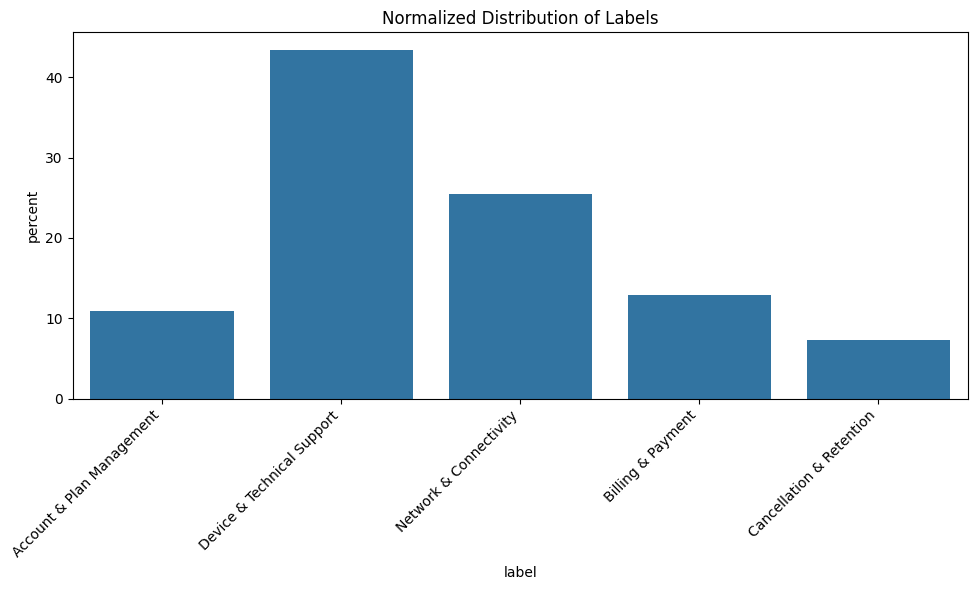

In [12]:
# Create a plot that displays the normalized distribution of labels in the dataset
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='label', stat='percent')
plt.xticks(rotation=45, ha='right')
plt.title('Normalized Distribution of Labels')
plt.tight_layout()
plt.show()

In [13]:
# Dropping all columns besides the tweets and labels
list_of_columns = list(df.columns)
list_of_columns.remove("text")
list_of_columns.remove("label")

df = df.drop(columns=list_of_columns)
df.head()

,text,label
8,the correct way to do it is via an ocs accoun...,Account & Plan Management
15,what else can i provide they refuse to help m...,Account & Plan Management
16,how i have my phone number and email thats it...,Device & Technical Support
17,dont know router is downstairs but its just t...,Device & Technical Support
18,just randomly boots me offline there it goes ...,Network & Connectivity


In [14]:
# Export the cleaned dataset
df.to_csv(DATA_DIR / "twcs_filtered_labeled_1_cleaned.csv", index=False)